# Feature Extraction


In [5]:
import os, glob, warnings
import numpy as np
import pandas as pd
import scipy.signal
from scipy.signal import find_peaks
from scipy.stats import median_abs_deviation, entropy
import pywt                     # wavelet
import antropy as ent          # sample entropy 
warnings.filterwarnings("ignore")

curfolder = os.getcwd()
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')
kinfiles = glob.glob(os.path.join(processedfolder, '*_kinematics.csv'))
distfiles = glob.glob(os.path.join(processedfolder, '*_distances.csv'))

## Configuration


In [6]:
# sides
SIDES = ["right", "left"]                 # Sapiens uses lowercase

# gross keypoints
ARM_JOINTS = ["shoulder", "elbow", "wrist"]

# aggregate columns 
TOTAL_ARM_SPEED = "arm_total_speed"
TOTAL_ARM_ACC   = "arm_total_acc"
TOTAL_ARM_JERK  = "arm_total_jerk"
TIME_COL        = "time_s"                

# ginfer keypoints
# finger -> {joint role: stem suffix}. MCP=third_joint, PIP=2, DIP=3, TIP=4.
FINGERS = {
    "thumb":         {"MCP": "thumb_third_joint",         "PIP": "thumb2",         "DIP": "thumb3",         "TIP": "thumb4"},
    "index":         {"MCP": "forefinger_third_joint",    "PIP": "forefinger2",    "DIP": "forefinger3",    "TIP": "forefinger4"},
    "middle":        {"MCP": "middle_finger_third_joint", "PIP": "middle_finger2", "DIP": "middle_finger3", "TIP": "middle_finger4"},
    "ring":          {"MCP": "ring_finger_third_joint",   "PIP": "ring_finger2",   "DIP": "ring_finger3",   "TIP": "ring_finger4"},
    "pinky":         {"MCP": "pinky_finger_third_joint",  "PIP": "pinky_finger2",  "DIP": "pinky_finger3",  "TIP": "pinky_finger4"},
}

def kp(side, stem):            # -> "right_forefinger4"
    return f"{side}_{stem}"

def tip_stem(finger):          # -> "forefinger4"
    return FINGERS[finger]["TIP"]

def mcp_stem(finger):
    return FINGERS[finger]["MCP"]

# distance column helper
def dist_col(side, j1, j2):    # "r8_5"  (magnitude column)
    p = "r" if side == "right" else "l"
    return f"{p}{j1}_{j2}"

FINGER_TIP_ID = {"thumb": 4, "index": 8, "middle": 12, "ring": 16, "pinky": 20}
FINGER_MCP_ID = {"thumb": 2, "index": 5, "middle": 9,  "ring": 13, "pinky": 17}  # thumb MCP=2

In [7]:
sample_kin1 = pd.read_csv(kinfiles[2])
sample_dist1 = pd.read_csv(distfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])
sample_dist2 = pd.read_csv(distfiles[500])

print(sample_kin1["FileID"].iloc[0], sample_kin2["FileID"].iloc[0])
print(sample_dist1["FileID"].iloc[0], sample_dist2["FileID"].iloc[0])

mp4_files = [f for f in os.listdir("GTST_sampled") if f.endswith(".mp4")]
video1 = [f for f in mp4_files if sample_kin1["FileID"].iloc[0] in f][0]
video2 = [f for f in mp4_files if sample_kin2["FileID"].iloc[0] in f][0]

GP01_ARBEITEN IP06_02_KAEMMEN
GP01_ARBEITEN IP06_02_KAEMMEN


IndexError: list index out of range

In [ ]:
import subprocess
from IPython.display import Video

dst1 = 'Temporary\output1.mp4'  # choose a suitable output path
Video(dst1, width=600, embed=True)

In [ ]:
dst2 = 'Temporary\output2.mp4'  # choose a suitable output path
Video(dst2, width=600, embed=True)

## 1 Gross / arm kinematics  (`*_kinematics.csv`)

These describe the **movement** dimension: magnitude, smoothness, rhythmicity, spatial extent, coordination, and (via the relative-speed columns) proximal-distal ratio.


In [8]:
# Bounding-box movement volume (spatial extent of a keypoint) 
def get_bbmv(df, side, joint):
    """Area of the x-y bounding box swept by one keypoint = how much space it covers."""
    xc, yc = kp(side, joint) + "_x", kp(side, joint) + "_y"
    if xc not in df.columns or yc not in df.columns:
        return np.nan
    return (df[xc].max() - df[xc].min()) * (df[yc].max() - df[yc].min())

sample_kin1 = pd.read_csv(kinfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])

print(get_bbmv(sample_kin1, "right", "wrist"))
print(get_bbmv(sample_kin2, "right", "wrist"))

0.0024607699129305565
0.2833723924250144


In [9]:
# Intermittency / dimensionless jerk (smoothness; higher = less smooth)  
def get_intermittency(jerk_values, speed_values):
    """Calculate intermittency (dimensionless jerk) from jerk and speed values.

    Args:
        jerk_values: Array-like of jerk values (acceleration derivative)
        speed_values: Array-like of speed values (velocity magnitude)

    Returns:
        float: Intermittency value (log of sum of squared jerk multiplied by
               (n^3 / max(speed^2)), or NaN if all speeds are zero)
    """
    jerk = np.asarray(jerk_values); speed = np.asarray(speed_values)
    if np.all(speed == 0):
        return np.nan
    return np.log(np.sum(jerk ** 2) * (len(speed) ** 3 / np.max(speed ** 2)))

print(get_intermittency(sample_kin1["right_wrist_jerk"], sample_kin1["right_wrist_speed"]))
print(get_intermittency(sample_kin2["right_wrist_jerk"], sample_kin2["right_wrist_speed"]))


23.653264997841443
23.526885697406087


In [10]:
# SPARC — spectral arc length smoothness  
# More robust smoothness measure than dimensionless jerk (less noise/duration sensitive).
# More negative = less smooth. Keep alongside intermittency; they disagree usefully.
def get_sparc(speed, fs, fc=10.0, amp_th=0.05):
    """Compute SPARC (Spectral Arc Length Smoothness) metric for motion smoothness.
    Args:
        speed: Array-like of speed values (units: arbitrary)
        fs: Sampling frequency (Hz)
        fc: Cutoff frequency for frequency domain analysis (Hz)
        amp_th: Amplitude threshold for frequency components to include
    Returns:
        SPARC score (more negative = less smooth)
    """
    speed = np.asarray(speed, float)
    if len(speed) < 8 or np.all(speed == 0):
        return np.nan
    N = int(2 ** np.ceil(np.log2(len(speed) * 4)))     # zero-pad for resolution
    Mf = np.abs(np.fft.rfft(speed, N))
    Mf = Mf / (Mf.max() + 1e-12)
    freq = np.fft.rfftfreq(N, d=1.0 / fs)
    keep = freq <= fc
    f, M = freq[keep], Mf[keep]
    inrange = M >= amp_th                                # adaptive cutoff
    if inrange.sum() < 2:
        return np.nan
    f, M = f[inrange], M[inrange]
    df_ = np.diff(f) / (f[-1] - f[0] + 1e-12)
    return -np.sum(np.sqrt(df_ ** 2 + np.diff(M) ** 2))

sr1 = round(len(sample_kin1) / (sample_kin1['time_s'].iloc[-1] - sample_kin1['time_s'].iloc[0]), 0) 
sr2 = round(len(sample_kin2) / (sample_kin2['time_s'].iloc[-1] - sample_kin2['time_s'].iloc[0]), 0) 

print(get_sparc(sample_kin1['right_wrist_speed'], sr1))
print(get_sparc(sample_kin2['right_wrist_speed'], sr2))


-1.5251843302008554
-2.9465520906240568


In [11]:
# Peaks / submovements   
def compute_peaks(df, col, fs, time_col=TIME_COL):
    """Compute peak characteristics from a signal column in a DataFrame.

    Args:
        df: DataFrame containing the signal data
        col: Name of the column containing the signal
        fs: Sampling frequency of the signal
        time_col: Name of the column containing time values (default: 'time_s')

    Returns:
        Dictionary containing:
        - peak_mean: Mean of peak values
        - peak_std: Standard deviation of peak values
        - peak_n: Number of peaks detected
        - peak_rate: Peak rate (peaks per second)
        - mod_depth: Modulation depth (mean peak - mean trough)
    """
    if col not in df.columns:
        return dict(peak_mean=np.nan, peak_std=np.nan, peak_n=np.nan,
                    peak_rate=np.nan, mod_depth=np.nan)
    scale = median_abs_deviation(df[col].dropna(), scale="normal")
    prominence = scale * 0.6
    distance = int((0.1 if "acc" in col else 0.2) * fs)
    sig = np.abs(df[col].values) if "acc" in col else df[col].values
    peaks, _ = find_peaks(sig, distance=max(distance, 1), prominence=prominence)
    vals = df[col].iloc[peaks]
    duration = df[time_col].iloc[-1] - df[time_col].iloc[0]

    # peak_rate (length-normalized)
    peak_rate = len(peaks) / duration if duration > 0 else np.nan

    # modulation depth = mean(peak) - mean(trough between peaks).
    # Shallow troughs = blended/co-articulated submovements; deep = segmented.
    mod_depth = np.nan
    if len(peaks) >= 2:
        troughs = [sig[peaks[i]:peaks[i+1]].min() for i in range(len(peaks) - 1)]
        mod_depth = float(np.mean(sig[peaks]) - np.mean(troughs))

    return dict(peak_mean=float(vals.mean()) if len(vals) else np.nan,
                peak_std=float(vals.std()) if len(vals) else np.nan,
                peak_n=len(peaks), peak_rate=peak_rate, mod_depth=mod_depth)

TIME_COL = 'time_s'
print(compute_peaks(sample_kin1, 'right_wrist_speed', sr1, TIME_COL))
print(compute_peaks(sample_kin2, 'right_wrist_speed', sr2, TIME_COL))

{'peak_mean': 0.05678229980163372, 'peak_std': 0.09813775730896032, 'peak_n': 5, 'peak_rate': 1.0638297872340425, 'mod_depth': 0.05267612969144907}
{'peak_mean': 1.9058849615545086, 'peak_std': 1.2460801774881791, 'peak_n': 3, 'peak_rate': 0.7627118644067797, 'mod_depth': 1.7164566861179915}


In [12]:
# Bimanual coupling (L<->R correlation) and asymmetry   #
def compute_arm_coupling(df, joints=("wrist", "elbow"), dims=("x", "y"), absolute=True):
    """Compute correlation between left and right arm movements across specified joints and dimensions.

    Args:
        df: DataFrame containing kinematic data with columns named as 'left_{joint}_{dim}' and 'right_{joint}_{dim}'
        joints: Tuple of joint names to analyze (default: wrist and elbow)
        dims: Tuple of dimensions to analyze (default: x and y)
        absolute: If True, return absolute correlation values (default: True)

    Returns:
        Mean correlation between left and right arm movements across specified joints and dimensions,
        or NaN if no valid pairs are found.
    """
    corrs = []
    for j in joints:
        for d in dims:
            lc, rc = f"left_{j}_{d}", f"right_{j}_{d}"
            if lc in df.columns and rc in df.columns:
                c = np.corrcoef(df[lc], df[rc])[0, 1]
                corrs.append(abs(c) if absolute else c)
    return np.nanmean(corrs) if corrs else np.nan

def compute_arm_asymmetry(df):
    """Compute asymmetry between left and right arm movements by comparing absolute speed sums.

    Args:
        df: DataFrame containing kinematic data with columns named as 'left_{joint}_speed' and 'right_{joint}_speed'

    Returns:
        Mean asymmetry between left and right arm movements across all joints,
        where negative values indicate right arm dominance and positive values indicate left arm dominance,
        or NaN if no valid pairs are found.
    """
    diffs = []
    for j in ARM_JOINTS:
        lc, rc = f"left_{j}_speed", f"right_{j}_speed"
        if lc in df.columns and rc in df.columns:
            diffs.append(np.nansum(np.abs(df[lc])) - np.nansum(np.abs(df[rc])))
    return np.nanmean(diffs) if diffs else np.nan

print(compute_arm_coupling(sample_kin1))
print(compute_arm_coupling(sample_kin2))
print(compute_arm_asymmetry(sample_kin1)) 
print(compute_arm_asymmetry(sample_kin2))

0.9062864198952019
0.5166187700946913
-0.3712471979378744
-39.099462662176784


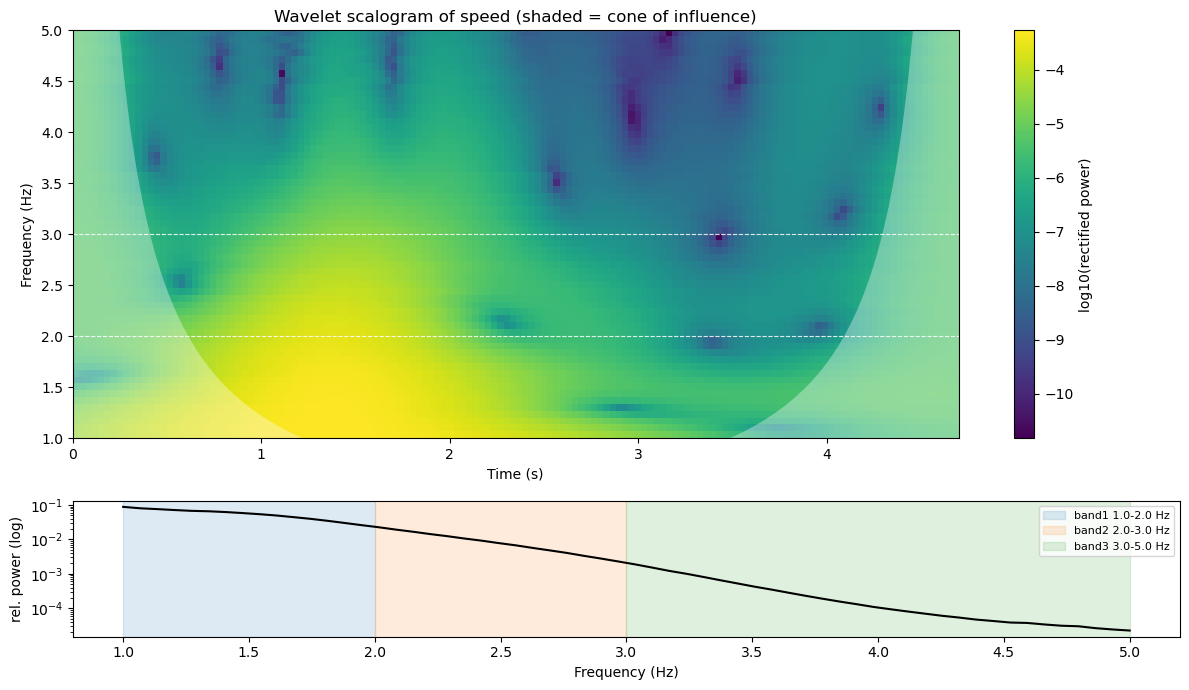

{'clip_dur_s': 4.7, 'band1_coverage': 1.0, 'band1_band_power': 0.8473594158554383, 'band1_centroid': 1.3799585137430381, 'band1_peak_freq': nan, 'band1_entropy': 0.9797208584624044, 'band2_coverage': 1.0, 'band2_band_power': 0.1424514295145258, 'band2_centroid': 2.3092816260303124, 'band2_peak_freq': nan, 'band2_entropy': 0.9253686610145786, 'band3_coverage': 1.0, 'band3_band_power': 0.010189154630035772, 'band3_centroid': 3.3557577912052077, 'band3_peak_freq': nan, 'band3_entropy': 0.7777053935318492}


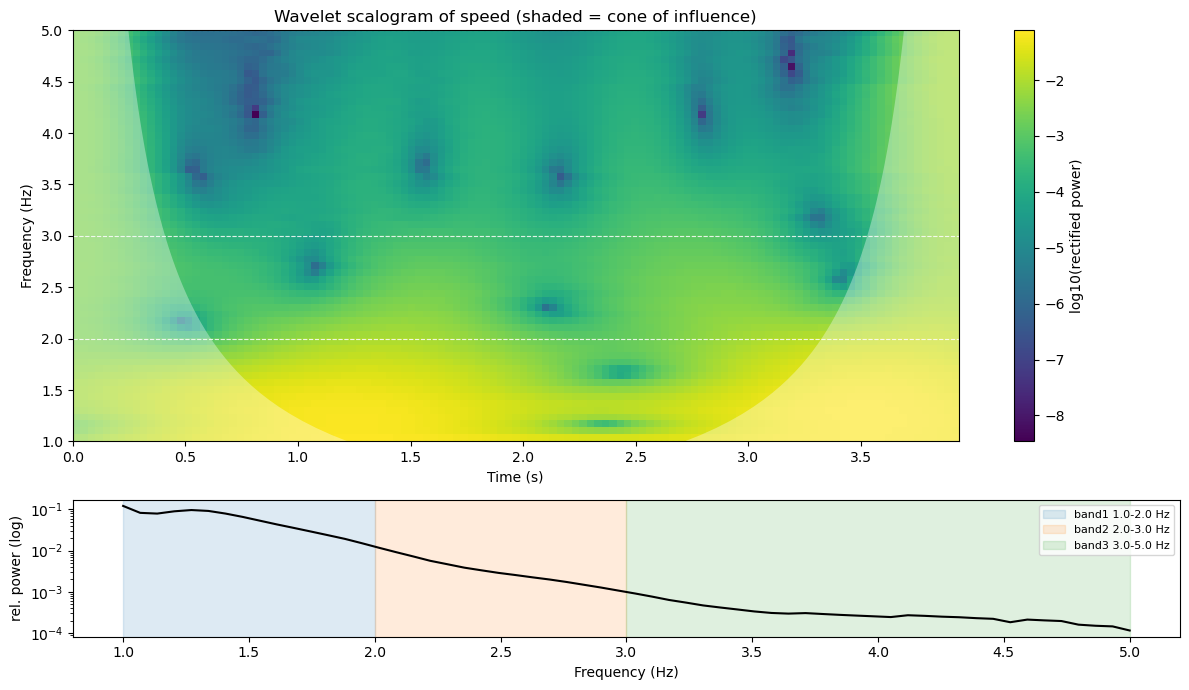

{'clip_dur_s': 3.933333333333333, 'band1_coverage': 1.0, 'band1_band_power': 0.9294230246168722, 'band1_centroid': 1.3317388726683637, 'band1_peak_freq': 1.271186440677966, 'band1_entropy': 0.9471751659472356, 'band2_coverage': 1.0, 'band2_band_power': 0.06104025533875236, 'band2_centroid': 2.292762916551023, 'band2_peak_freq': nan, 'band2_entropy': 0.909056065674681, 'band3_coverage': 1.0, 'band3_band_power': 0.009536720044375587, 'band3_centroid': 3.7375961781580584, 'band3_peak_freq': 3.711864406779661, 'band3_entropy': 0.9607789818083002}


In [13]:
# Wavelet rhythmicity (3 bands)  
import numpy as np
import pywt


def wavelet_rhythmicity(speed, time, bands=((1.0, 2.0), (2.0, 3.0), (3.0, 5.0)),
                        n_freqs=60, wavelet="cmor1.5-1.0", fs=None,
                        min_valid_frac=0.25, plot=False):
    """Wavelet band metrics for a kinematic speed signal.

    Changes vs. the original:
      - sampling rate taken from `time` (fs only used as a consistency check)
      - signal demeaned before the CWT (speed is >= 0; the offset creates edge steps)
      - power rectified by scale (Liu et al., 2007) to remove the low-frequency bias
      - cone of influence (COI) masked before time-averaging
      - peak frequency only reported for a true local maximum inside the band
        (otherwise NaN), so a decaying spectrum no longer yields "peak = lower edge"
      - band entropy normalised by log(n_bins) so bands of different width compare

    Args:
        speed: speed signal (array-like)
        time: time stamps in seconds (array-like, same length)
        bands: frequency bands (Hz) as (low, high) tuples
        n_freqs: number of linearly spaced analysis frequencies
        wavelet: pywt complex Morlet name, "cmorB-C"
        fs: optional sampling rate, checked against `time`
        min_valid_frac: minimum fraction of samples outside the COI for a
            frequency row to be used
        plot: draw scalogram (COI shaded) and mean spectrum (log y)

    Returns:
        dict with, per band: band_power (relative to all usable power in the
        analysed range), centroid, peak_freq (NaN if no interior peak),
        entropy (0-1), coverage (fraction of band bins outside COI limits).
    """
    speed = np.asarray(speed, float)
    time = np.asarray(time, float)
    if np.isnan(speed).any():
        ok = ~np.isnan(speed)
        speed = np.interp(time, time[ok], speed[ok])

    dt = np.median(np.diff(time))
    if fs is not None and not np.isclose(fs, 1 / dt, rtol=0.01):
        raise ValueError(f"fs={fs} but time vector implies {1 / dt:.3f} Hz")

    x = speed - speed.mean()

    fmin = min(b[0] for b in bands)
    fmax = max(b[1] for b in bands)
    freqs = np.linspace(fmin, fmax, n_freqs)
    scales = pywt.central_frequency(wavelet) / (freqs * dt)
    coef, _ = pywt.cwt(x, scales, wavelet, sampling_period=dt)
    power = np.abs(coef) ** 2 / scales[:, None]  # bias rectification

    # Cone of influence: e-folding time of edge effects = sqrt(2) * sigma_t
    B, C = (float(v) for v in wavelet[4:].split("-"))
    sigma_t = C * np.sqrt(B / 2) / freqs           # seconds
    efold = np.sqrt(2) * sigma_t
    t = time - time[0]
    T = t[-1]
    coi = (t[None, :] >= efold[:, None]) & (t[None, :] <= T - efold[:, None])
    valid_frac = coi.mean(axis=1)
    usable = valid_frac >= max(min_valid_frac, 1e-9)

    mp = np.full(n_freqs, np.nan)
    if usable.any():
        mp[usable] = np.nanmean(np.where(coi, power, np.nan)[usable], axis=1)
    total = np.nansum(mp)
    mp_rel = mp / total if total > 0 else mp

    out = {"clip_dur_s": float(T)}
    for i, (a, b) in enumerate(bands):
        key = f"band{i + 1}"
        upper = (freqs <= b) if np.isclose(b, fmax) else (freqs < b)
        m = (freqs >= a) & upper
        mu = m & usable
        out[f"{key}_coverage"] = float(mu.sum() / max(m.sum(), 1))
        if mu.sum() == 0 or np.nansum(mp_rel[mu]) == 0:
            for k in ("band_power", "centroid", "peak_freq", "entropy"):
                out[f"{key}_{k}"] = np.nan
            continue
        bf, bp = freqs[mu], mp_rel[mu]
        p = bp / bp.sum()
        out[f"{key}_band_power"] = float(bp.sum())
        out[f"{key}_centroid"] = float(np.sum(bf * p))
        # interior local maxima of the full spectrum that fall inside this band
        idx = np.where(mu)[0]
        peaks = [k for k in idx if 0 < k < n_freqs - 1
                 and mp_rel[k] > mp_rel[k - 1] and mp_rel[k] > mp_rel[k + 1]]
        out[f"{key}_peak_freq"] = (float(freqs[max(peaks, key=lambda k: mp_rel[k])])
                                   if peaks else np.nan)
        out[f"{key}_entropy"] = (float(-np.sum(p * np.log(p + 1e-12)) / np.log(len(p)))
                                 if len(p) > 1 else np.nan)

    if plot:
        import matplotlib.pyplot as plt
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7),
                                       gridspec_kw={"height_ratios": [3, 1]})
        im = ax1.imshow(np.log10(power + 1e-12), aspect="auto", origin="lower",
                        extent=[time[0], time[-1], freqs[0], freqs[-1]], cmap="viridis")
        ax1.fill_betweenx(freqs, time[0], np.minimum(time[0] + efold, time[-1]),
                          color="w", alpha=0.35, lw=0)
        ax1.fill_betweenx(freqs, np.maximum(time[-1] - efold, time[0]), time[-1],
                          color="w", alpha=0.35, lw=0)
        for (a, b) in bands:
            ax1.axhline(a, color="w", lw=0.8, ls="--", alpha=0.6)
            ax1.axhline(b, color="w", lw=0.8, ls="--", alpha=0.6)
        fig.colorbar(im, ax=ax1, label="log10(rectified power)")
        ax1.set_ylabel("Frequency (Hz)")
        ax1.set_xlabel("Time (s)")
        ax1.set_title("Wavelet scalogram of speed (shaded = cone of influence)")
        ax2.semilogy(freqs, mp_rel, color="k")
        for i, (a, b) in enumerate(bands):
            ax2.axvspan(a, b, alpha=0.15, color=f"C{i}", label=f"band{i + 1} {a}-{b} Hz")
        ax2.set_xlabel("Frequency (Hz)")
        ax2.set_ylabel("rel. power (log)")
        ax2.legend(fontsize=8)
        plt.tight_layout()
        plt.show()

    return out

print(wavelet_rhythmicity(sample_kin1['right_wrist_speed'], sample_kin1['time_s'], fs=sr1, plot=True))
print(wavelet_rhythmicity(sample_kin2['right_wrist_speed'], sample_kin2['time_s'], fs=sr2, plot=True))

In [14]:
# Proximalization index (rel/abs)   
# wrist absolute speed includes elbow transport; wrist relspeed is elbow-removed articulation.
# ratio -> 0 : wrist just carried by the arm (proximalized).  ratio -> 1 : independent forearm
# rotation (distal). Mean over available arm joints that have a relspeed column.
def get_proximalization_index(df):
    """Calculate the proximalization index by computing the ratio of relative to absolute speeds
    for wrist and elbow joints across both sides. Returns the mean ratio or NaN if no valid data."""
    ratios = []
    for side in SIDES:
        for j in ("wrist", "elbow"):
            ab, rel = f"{side}_{j}_speed", f"{side}_{j}_relspeed"
            if ab in df.columns and rel in df.columns:
                a = df[ab].to_numpy(); r = df[rel].to_numpy()
                denom = np.nanmedian(a)
                if denom > 1e-9:
                    ratios.append(np.nanmedian(r) / denom)
    return np.nanmean(ratios) if ratios else np.nan

print(get_proximalization_index(sample_kin1))
print(get_proximalization_index(sample_kin2))


1.2258518904332973
0.6911449042008195


## 2 Hand / handshape features  (`*_hand_distances.csv` + finger cols of kinematics)

Here we calculate handshape geometry a finger independence.

In [15]:
# Handshape geometry from distance columns   
def feature_adjacent_fingertip_spread(df, side):
    """Mean & std of adjacent fingertip gaps (thumb-index, index-middle, ...)."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_thumb_index_distance(df, side):                # aperture / pinch
    """Calculate mean and standard deviation of thumb-index distance."""
    c = dist_col(side, 4, 8)
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

def feature_mcp_tip_distance(df, side):                     # overall flexion (tip->MCP)
    """Mean & std of MCP-tip distances (thumb, index, middle, ring, pinky)."""
    cols = [dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])
            for f in ["thumb","index","middle","ring","pinky"]]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

# thumb opposition — thumb tip to pinky MCP (a distinct phonological handshape axis)
def feature_thumb_opposition(df, side):
    """Calculate mean and standard deviation of thumb tip to pinky MCP distance."""
    c = dist_col(side, 4, FINGER_MCP_ID["pinky"])
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

# spread
print(feature_adjacent_fingertip_spread(sample_dist1, "right"))
print(feature_adjacent_fingertip_spread(sample_dist2, "right"))

# thumb-index distance
print(feature_thumb_index_distance(sample_dist1, "right"))
print(feature_thumb_index_distance(sample_dist2, "right"))

# mcp-tip distance
print(feature_mcp_tip_distance(sample_dist1, "right"))
print(feature_mcp_tip_distance(sample_dist2, "right"))

# thumb opposition
print(feature_thumb_opposition(sample_dist1, "right"))
print(feature_thumb_opposition(sample_dist2, "right"))

(0.5809732984861569, 0.35844902885508634)
(0.31379181035282594, 0.07419964635665426)
(0.8898046022214737, 0.08752315681954034)
(0.31890188555111865, 0.16612689742898823)
(1.3351384197229066, 0.4006715330281425)
(0.9398215498649654, 0.12167019858274095)
(1.3941572367632853, 0.06522716482100399)
(1.3640581364731605, 0.7757515855765891)


In [16]:
# Handshape size & variability  
def feature_handshape_size(df, side):
    """Calculate mean and standard deviation of handshape features."""
    p = "r" if side == "right" else "l"
    cols = [c for c in df.columns
            if c.startswith(p) and "_" in c
            and not c.endswith(("_x","_y","_speed","_acc","_jerk"))
            and df[c].dtype != object]
    print(cols)
    if not cols: return np.nan, np.nan
    return df[cols].mean(axis=1).mean(), df[cols].std(axis=1).mean()

def feature_handshape_variability(df, side):
    """Total temporal SD of the adjacent-fingertip gaps = how much handshape changes."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    return df[cols].std().sum() if cols else np.nan

# handshape size
print("handshape size")
print(feature_handshape_size(sample_dist1, "right"))
print(feature_handshape_size(sample_dist2, "right"))

# handshape variability
print("handshape variability")
print(feature_handshape_variability(sample_dist1, "right"))
print(feature_handshape_variability(sample_dist2, "right"))


handshape size
['r4_2', 'r4_1', 'r3_1', 'r4_17', 'r2_0', 'r3_0', 'r4_0', 'r8_6', 'r7_5', 'r8_5', 'r6_0', 'r7_0', 'r8_0', 'r12_10', 'r11_9', 'r12_9', 'r10_0', 'r11_0', 'r12_0', 'r16_14', 'r15_13', 'r16_13', 'r14_0', 'r15_0', 'r16_0', 'r20_18', 'r19_17', 'r20_17', 'r18_0', 'r19_0', 'r20_0', 'r4_8', 'r8_12', 'r12_16', 'r16_20']
(10.898333605135887, 11.58717288284408)
['r4_2', 'r4_1', 'r3_1', 'r4_17', 'r2_0', 'r3_0', 'r4_0', 'r8_6', 'r7_5', 'r8_5', 'r6_0', 'r7_0', 'r8_0', 'r12_10', 'r11_9', 'r12_9', 'r10_0', 'r11_0', 'r12_0', 'r16_14', 'r15_13', 'r16_13', 'r14_0', 'r15_0', 'r16_0', 'r20_18', 'r19_17', 'r20_17', 'r18_0', 'r19_0', 'r20_0', 'r4_8', 'r8_12', 'r12_16', 'r16_20']
(10.066930728342456, 10.868046159002994)
handshape variability
0.2541134700313384
0.6301137116273903


In [33]:
d = sample_dist1
cols = [c for c in d.columns if c.startswith("r") and "_" in c
        and not c.endswith(("_x","_y","_speed","_acc","_jerk"))]
print(d[cols].mean().sort_values(ascending=False).round(2))



r4_0      24.45
r6_0      24.43
r8_0      24.42
r7_0      24.42
r3_0      24.40
r12_0     24.28
r2_0      24.26
r11_0     24.23
r10_0     24.21
r16_0     24.02
r15_0     23.94
r14_0     23.89
r20_0     23.42
r18_0     23.42
r19_0     23.39
r12_9      1.73
r8_5       1.65
r16_13     1.48
r4_1       1.40
r4_17      1.39
r11_9      1.28
r7_5       1.21
r15_13     1.08
r3_1       0.98
r12_10     0.97
r8_6       0.92
r20_17     0.91
r4_2       0.91
r4_8       0.89
r16_20     0.87
r16_14     0.86
r19_17     0.63
r20_18     0.55
r12_16     0.41
r8_12      0.16
dtype: float64


In [17]:
# Fingertip dynamics 

def _tip_mcp_speed_cols(df, side):
    """Identifies and returns columns in the DataFrame that contain speed data between fingertip and MCP joints for specified fingers (excluding thumb)."""
    cols = [f"{dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])}_speed"
            for f in ["index","middle","ring","pinky"]]     # thumb handled separately
    return [c for c in cols if c in df.columns]

def feature_fingertip_speed(df, side):                      
    """Calculates the mean and standard deviation of fingertip speed between MCP and fingertip joints for specified fingers (excluding thumb)."""
    cols = _tip_mcp_speed_cols(df, side)
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_fingertip_intermittency(df, side):
    """Flexion smoothness: dimensionless jerk (intermittency) of each finger's
    tip-MCP flexion signal, averaged over index, middle, ring and pinky (thumb excluded).

    Uses the same get_intermittency() as the gross arm signal, so fine and gross
    smoothness are on the same scale (higher = less smooth). Replaces the old
    mean of signed jerk, which telescoped to (acc_end - acc_start) / duration.
    """
    vals = []
    for sp_col in _tip_mcp_speed_cols(df, side):
        j_col = sp_col.replace("_speed", "_jerk")
        if j_col not in df.columns:
            continue
        sub = df[[sp_col, j_col]].dropna()
        if len(sub) < 3:
            continue
        v = get_intermittency(sub[j_col].to_numpy(), sub[sp_col].to_numpy())
        if np.isfinite(v):
            vals.append(v)
    return np.mean(vals) if vals else np.nan

print("fingertip speed")
print(feature_fingertip_speed(sample_dist1, "right"))
print(feature_fingertip_speed(sample_dist2, "right"))

print("fingertip jerk")
print(feature_fingertip_intermittency(sample_dist1, "right"))
print(feature_fingertip_intermittency(sample_dist2, "right"))

fingertip speed
(0.06154233154516987, 0.013000661731451854)
(0.8266968227913774, 0.10679937022740925)
fingertip jerk
24.003359091793595
23.971528047449127


In [18]:
# Finger independence   
# Correlate FLEXION speeds (tip->MCP distance speed), which have wrist motion removed.
# independence = 1 - mean pairwise corr.  High = fingers move independently (native-signer-like).
def feature_finger_independence(df, side):
    pairs = [("index","middle"), ("middle","ring"), ("ring","pinky")]
    corrs = []
    for a, b in pairs:
        ca = f"{dist_col(side, FINGER_TIP_ID[a], FINGER_MCP_ID[a])}_speed"
        cb = f"{dist_col(side, FINGER_TIP_ID[b], FINGER_MCP_ID[b])}_speed"
        if ca in df.columns and cb in df.columns:
            corrs.append(df[ca].corr(df[cb]))
    return 1 - np.nanmean(corrs) if corrs else np.nan

print("finger indepenedence")
print(feature_finger_independence(sample_dist1, "right"))
print(feature_finger_independence(sample_dist2, "right"))

finger indepenedence
0.20007826714658516
0.2886500097305662


In [19]:
# Speed entropy of finger flexion (variability of the signal)   
def feature_finger_speed_entropy(df, side, finger="index"):
    """Calculate the entropy of finger speed variability from distance data."""
    c = f"{dist_col(side, FINGER_TIP_ID[finger], FINGER_MCP_ID[finger])}_speed"
    if c not in df.columns: return np.nan
    hist, _ = np.histogram(df[c].dropna(), bins=30, density=True)
    return entropy(hist + 1e-8)

print(feature_finger_speed_entropy(sample_dist1, "right"))
print(feature_finger_speed_entropy(sample_dist2, "right"))

2.6828521078507483
3.1253831509881005


## 3 Per-file assembly

`extract_gross_features` and `extract_hand_features` each return a flat dict; `extract_all` merges them for one file. 

In [20]:
def _mean_sides(fn, *dfs):
    """Call fn(*dfs, side) for each side, return nan-mean of the (scalar or tuple) results.
    Handles fns that return a scalar OR a (mean, std) tuple -> returns pooled scalar/tuple."""
    vals = [fn(*dfs, side) for side in SIDES]
    if isinstance(vals[0], tuple):
        return tuple(np.nanmean([v[i] for v in vals]) for i in range(len(vals[0])))
    return np.nanmean(vals)


def fname(name: str, domain: str, family: str) -> str:
    """Format a feature column name as domain__family__name."""
    return f"{domain}__{family}__{name}"

def extract_gross_features(df, fs):
    f = {}
    # aggregate arm-speed descriptives (uses your total_arm_* columns)
    for col, tag in [(TOTAL_ARM_SPEED, "arm_speed"), (TOTAL_ARM_ACC, "arm_acc")]:
        if col in df.columns:
            f[fname(f"{tag}_Gmean", "gross", "magnitude")]   = df[col].mean()
            f[fname(f"{tag}_Gstd",  "gross", "variability")] = df[col].std()
            pk = compute_peaks(df, col, fs)
            f[fname(f"{tag}_peak_mean", "gross", "magnitude")]   = pk["peak_mean"]
            f[fname(f"{tag}_peak_std",  "gross", "variability")] = pk["peak_std"]
            f[fname(f"{tag}_peak_n",    "gross", "rhythm")]      = pk["peak_n"]
            f[fname(f"{tag}_peak_rate", "gross", "rhythm")]      = pk["peak_rate"]
            f[fname(f"{tag}_mod_depth", "gross", "rhythm")]      = pk["mod_depth"]
    # integral / smoothness / rhythm on the total_arm signal
    if TOTAL_ARM_SPEED in df.columns:
        f[fname("arm_speed_integral", "gross", "magnitude")] = np.trapz(df[TOTAL_ARM_SPEED].values, dx=1/fs)
        f[fname("arm_speed_sampen", "gross", "rhythm")] = ent.sample_entropy(df[TOTAL_ARM_SPEED].values, order=2)
        f[fname("arm_intermittency", "gross", "smoothness")] = get_intermittency(
            df.get(TOTAL_ARM_JERK, pd.Series(dtype=float)), df[TOTAL_ARM_SPEED])
        f[fname("arm_sparc", "gross", "smoothness")] = get_sparc(df[TOTAL_ARM_SPEED].values, fs)
        for k, v in wavelet_rhythmicity(df[TOTAL_ARM_SPEED], df[TIME_COL], fs=fs).items():
            f[fname(f"{k}_totalarm", "gross", "rhythm")] = v

    # BBMV
    bbmv_total = np.nansum([get_bbmv(df, side, j) for side in SIDES for j in ARM_JOINTS])
    f[fname("bbmv_arms_total", "gross", "magnitude")] = bbmv_total

    # coordination — intrinsically bilateral, computed once (NOT side-averaged)
    f[fname("arm_coupling",  "gross", "coordination")] = compute_arm_coupling(df)
    f[fname("arm_asymmetry", "gross", "coordination")] = compute_arm_asymmetry(df)
    f[fname("proximalization_index", "gross", "proxdist")] = get_proximalization_index(df)  # already means over sides internally
    return f


def extract_hand_features(df_kin, df_dist):
    f = {}
    # geometry / handshape: mean over L and R ---
    m, sd = _mean_sides(feature_adjacent_fingertip_spread, df_dist)
    f[fname("fingertip_spread_mean", "fine", "handshape")]   = m
    f[fname("fingertip_spread_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_index_distance, df_dist)
    f[fname("thumb_index_mean", "fine", "handshape")]   = m
    f[fname("thumb_index_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_mcp_tip_distance, df_dist)
    f[fname("mcp_tip_mean", "fine", "handshape")]   = m
    f[fname("mcp_tip_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_opposition, df_dist)
    f[fname("thumb_opposition_mean", "fine", "handshape")]   = m
    f[fname("thumb_opposition_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_handshape_size, df_dist)
    f[fname("handshape_size_mean", "fine", "handshape")]   = m
    f[fname("handshape_size_std",  "fine", "variability")] = sd

    f[fname("handshape_variability", "fine", "variability")] = np.nanmean(
        [feature_handshape_variability(df_dist, side) for side in SIDES])

    # dynamics (gross-independent): mean over L and R 
    m, sd = _mean_sides(feature_fingertip_speed, df_dist)
    f[fname("flexion_speed_mean", "fine", "magnitude")]   = m
    f[fname("flexion_speed_std",  "fine", "variability")] = sd

    f[fname("flexion_intermittency", "fine", "smoothness")] = np.nanmean(
        [feature_fingertip_intermittency(df_dist, side) for side in SIDES])

    # coordination — average the two hands' independence/correlations 
    f[fname("finger_independence", "fine", "coordination")] = np.nanmean(
        [feature_finger_independence(df_dist, side) for side in SIDES])

    f[fname("flexion_entropy", "fine", "variability")] = np.nanmean(
        [feature_finger_speed_entropy(df_dist, side, "index") for side in SIDES])
    return f

def extract_all(df_kin, df_dist, fs):
    return {**extract_gross_features(df_kin, fs), **extract_hand_features(df_kin, df_dist)}

## 4 Batch loop

In [21]:
processedfolder = os.path.join(curfolder, "Sapiens_Processed")   # <-- set curfolder above
datasetsfolder  = os.path.join(curfolder, "Datasets")

kin_files = sorted(glob.glob(os.path.join(processedfolder, "*_kinematics.csv")))

rows = []
for kin_file in kin_files:
    print("processing", os.path.basename(kin_file))

    if os.path.basename(kin_file).startswith('LP'):
        continue

    dist_file = kin_file.replace("_kinematics.csv", "_hand_distances.csv")
    if not os.path.exists(dist_file):
        print("no distance file for", os.path.basename(kin_file)); continue

    df_kin  = pd.read_csv(kin_file)
    df_dist = pd.read_csv(dist_file)
    fid = df_kin["FileID"].iloc[0]

    # skip practice trials
    # if any(t in fid for t in ("LIGHTNING", "TO-HEAR", "GOAL")):
    #     continue

    fs_count = round(len(df_kin) / (df_kin[TIME_COL].iloc[-1] - df_kin[TIME_COL].iloc[0]))
    print(fs_count)
    fs = 30

    feats = extract_all(df_kin, df_dist, fs)
    feats["fileID"] = fid

    # group identification
    if "GtST" in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Sign'
    elif 'GP' in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Gesture'
    elif fid.startswith("LP") or fid.startswith("IP"):
        feats["group"] = "_".join(fid.split("_")[:2])
        if "_01_" in fid:
            feats["groupID"] = 'Learner_1'
        elif "_02_" in fid:
            feats["groupID"] = 'Learner_2'
        else:
            print('error')
            break

    elif "ViCom" in fid:
        feats["group"] = "ViCom"
        feats["groupID"] = "Sign"
    else:
        print("unparsed fileID:", fid); continue

    # concept
    try:
        if "GtST" in fid:   feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "GP" in fid:   feats["concept"] = fid.split("_")[1].split(".")[0]
        elif "LP" in fid or "IP" in fid: feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "ViCom" in fid: feats["concept"] = fid.split("_")[3].split(".")[0]
    except IndexError:
        feats["concept"] = np.nan
    fix = {"TO-PICK":"TO-PLUCK", "TO-MOVE-HOUSES":"TO-MOVE", "VIDEO-GAME":"VIDEOGAME"}
    feats["concept"] = fix.get(feats.get("concept"), feats.get("concept"))

    rows.append(feats)

features_df = pd.DataFrame(rows)
print(features_df.shape, "->", features_df["group"].value_counts().to_dict() if len(features_df) else "empty")

features_df['pcnID'] = features_df['group'].str.split("_").str[0]

features_df.to_csv(os.path.join(datasetsfolder, "sapiens_features.csv"), index=False)

processing GP01_ADLER_kinematics.csv
30
['r4_2', 'r4_1', 'r3_1', 'r4_17', 'r2_0', 'r3_0', 'r4_0', 'r8_6', 'r7_5', 'r8_5', 'r6_0', 'r7_0', 'r8_0', 'r12_10', 'r11_9', 'r12_9', 'r10_0', 'r11_0', 'r12_0', 'r16_14', 'r15_13', 'r16_13', 'r14_0', 'r15_0', 'r16_0', 'r20_18', 'r19_17', 'r20_17', 'r18_0', 'r19_0', 'r20_0', 'r4_8', 'r8_12', 'r12_16', 'r16_20']
['l4_2', 'l4_1', 'l3_1', 'l4_17', 'l2_0', 'l3_0', 'l4_0', 'l8_6', 'l7_5', 'l8_5', 'l6_0', 'l7_0', 'l8_0', 'l12_10', 'l11_9', 'l12_9', 'l10_0', 'l11_0', 'l12_0', 'l16_14', 'l15_13', 'l16_13', 'l14_0', 'l15_0', 'l16_0', 'l20_18', 'l19_17', 'l20_17', 'l18_0', 'l19_0', 'l20_0', 'l4_8', 'l8_12', 'l12_16', 'l16_20']
processing GP01_ANSTECKEN_kinematics.csv
30
['r4_2', 'r4_1', 'r3_1', 'r4_17', 'r2_0', 'r3_0', 'r4_0', 'r8_6', 'r7_5', 'r8_5', 'r6_0', 'r7_0', 'r8_0', 'r12_10', 'r11_9', 'r12_9', 'r10_0', 'r11_0', 'r12_0', 'r16_14', 'r15_13', 'r16_13', 'r14_0', 'r15_0', 'r16_0', 'r20_18', 'r19_17', 'r20_17', 'r18_0', 'r19_0', 'r20_0', 'r4_8', 'r8_12', 

## 5 Aftermath

In [22]:
features_df.head()

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_intermittency,fine__coordination__finger_independence,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.942586,1.048086,3.435209,0.035561,2,0.425532,3.302515,3.740303,3.719707,7.665705,...,1.645175,0.286774,24.120227,0.022418,2.645388,GP01_ADLER,GP01,Gesture,ADLER,GP01
1,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.308611,0.041215,24.401422,0.460921,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
2,0.054714,0.060512,0.132675,0.114165,4,0.851064,0.075588,0.178191,0.237700,0.433752,...,0.060704,0.010147,24.032740,0.234046,2.549171,GP01_ARBEITEN,GP01,Gesture,ARBEITEN,GP01
3,0.070113,0.093247,0.164349,0.152769,5,1.056338,0.070968,0.249783,0.356810,0.528607,...,0.082413,0.022108,24.166783,0.303959,2.296957,GP01_ARGUMENTIEREN,GP01,Gesture,ARGUMENTIEREN,GP01
4,1.113370,0.674370,2.132207,0.727866,5,1.056338,1.388926,3.626271,2.956483,6.262319,...,0.760086,0.091925,24.479000,0.196925,2.816355,GP01_BLITZ,GP01,Gesture,BLITZ,GP01


In [23]:
# check missing values
nan_pct = features_df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("features >50% NaN (check names in §0):")
print(nan_pct[nan_pct > 50])

# remove gross__rhythm__band2_peak_freq_totalarm
features_df = features_df.drop(columns=["gross__rhythm__band2_peak_freq_totalarm"])

# also remove all columns containing *coverage_totalarm (they are just for checking)
features_df = features_df.drop(columns=[c for c in features_df.columns if "coverage_totalarm" in c])
# and gross__rhythm__clip_dur_s_totalarm
features_df = features_df.drop(columns=["gross__rhythm__clip_dur_s_totalarm"])


features >50% NaN (check names in §0):
gross__rhythm__band2_peak_freq_totalarm    81.7
dtype: float64


In [24]:
features_df["pcnID"].value_counts().to_dict()
features_df["groupID"].value_counts().to_dict()

{'Gesture': 295, 'Learner_2': 264, 'Learner_1': 252, 'Sign': 250}

In [25]:
features_df_clean = features_df[~features_df['group'].str.startswith('LP')]
features_df_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noLP.csv"), index=False)

In [26]:
features_df_clean["groupID"].value_counts().to_dict()

{'Gesture': 295, 'Learner_2': 264, 'Learner_1': 252, 'Sign': 250}

In [27]:
# Keep only those sampled within no-concept randomization

noconcept = pd.read_csv(os.path.join(datasetsfolder, 'sampled_files_noconcept.csv'), index_col=0)
noconcept['filename'] = noconcept['file'].replace(" .mp4", "", regex=True)
noconcept['filename'] = noconcept['file'].replace(".mp4", "", regex=True)

features_df_NC = features_df[features_df['fileID'].isin(noconcept['filename'])]
features_df_NC

features_df_NC_clean = features_df_NC[~features_df_NC['group'].str.startswith('LP')]
features_df_NC_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noconcept_noLP.csv"), index=False)

In [28]:
features_df_NC_clean["groupID"].value_counts().to_dict()

{'Gesture': 250, 'Sign': 250, 'Learner_1': 250, 'Learner_2': 250}

Check if we have all files from sampling file

In [29]:
import os, glob
import pandas as pd

sampled_csv = os.path.join(curfolder, "Datasets", "sampled_files_noconcept.csv")
kin_folder  = os.path.join(curfolder, "Sapiens_Processed")      # folder with *_kinematics.csv
suffix      = "_kinematics.csv"

sampled = pd.read_csv(sampled_csv, index_col=0)

# get rid of those which pcnID contains LP (these we excluded)
sampled = sampled[~sampled["pcnID"].str.contains("LP")]

sampled["stem"] = sampled["file"].str.replace(r"\.mp4$", "", regex=True)

kin_stems = {os.path.basename(p)[: -len(suffix)]
             for p in glob.glob(os.path.join(kin_folder, "**", f"*{suffix}"), recursive=True)}

missing = sampled[~sampled["stem"].isin(kin_stems)]

print(f"{len(missing)} of {len(sampled)} sampled files have no kinematics file")
missing[["group", "pcnID", "file"]]

# save it
missing.to_csv(os.path.join(curfolder, "missing_kinematics.csv"))

0 of 1000 sampled files have no kinematics file


In [30]:
missing

,group,pcnID,file,path,stem


## 6 UMAP (visual purpose only)

In [31]:
import plotly.express as px, pandas as pd, umap
from sklearn.preprocessing import StandardScaler

feat_df = features_df_clean.copy()

meta_cols = ['fileID', 'group', 'concept', 'groupID']        # add meta columns
meta_cols = [c for c in meta_cols if c in feat_df.columns]

num = feat_df.select_dtypes('number')
num = num.loc[:, num.isna().mean() < 0.5]         # keep cols <50% NaN

keep = num.dropna().index                          
num  = num.loc[keep]
meta = feat_df.loc[keep, meta_cols]              

scaled   = StandardScaler().fit_transform(num)
embedding = umap.UMAP(random_state=42).fit_transform(scaled)

plot_df = pd.DataFrame(embedding, columns=['x', 'y'], index=keep)
plot_df = pd.concat([plot_df, meta], axis=1)       # aligned by index, not by position

fig = px.scatter(plot_df, x='x', y='y',
                 color='groupID' if 'groupID' not in plot_df else 'groupID',
                 symbol='group', hover_name='concept',
                 title='UMAP projection', opacity=0.6)
fig.update_layout(width=900, height=800, yaxis=dict(scaleanchor='x', scaleratio=1))
fig.show()

## 7 Cross-correlation

<Axes: >

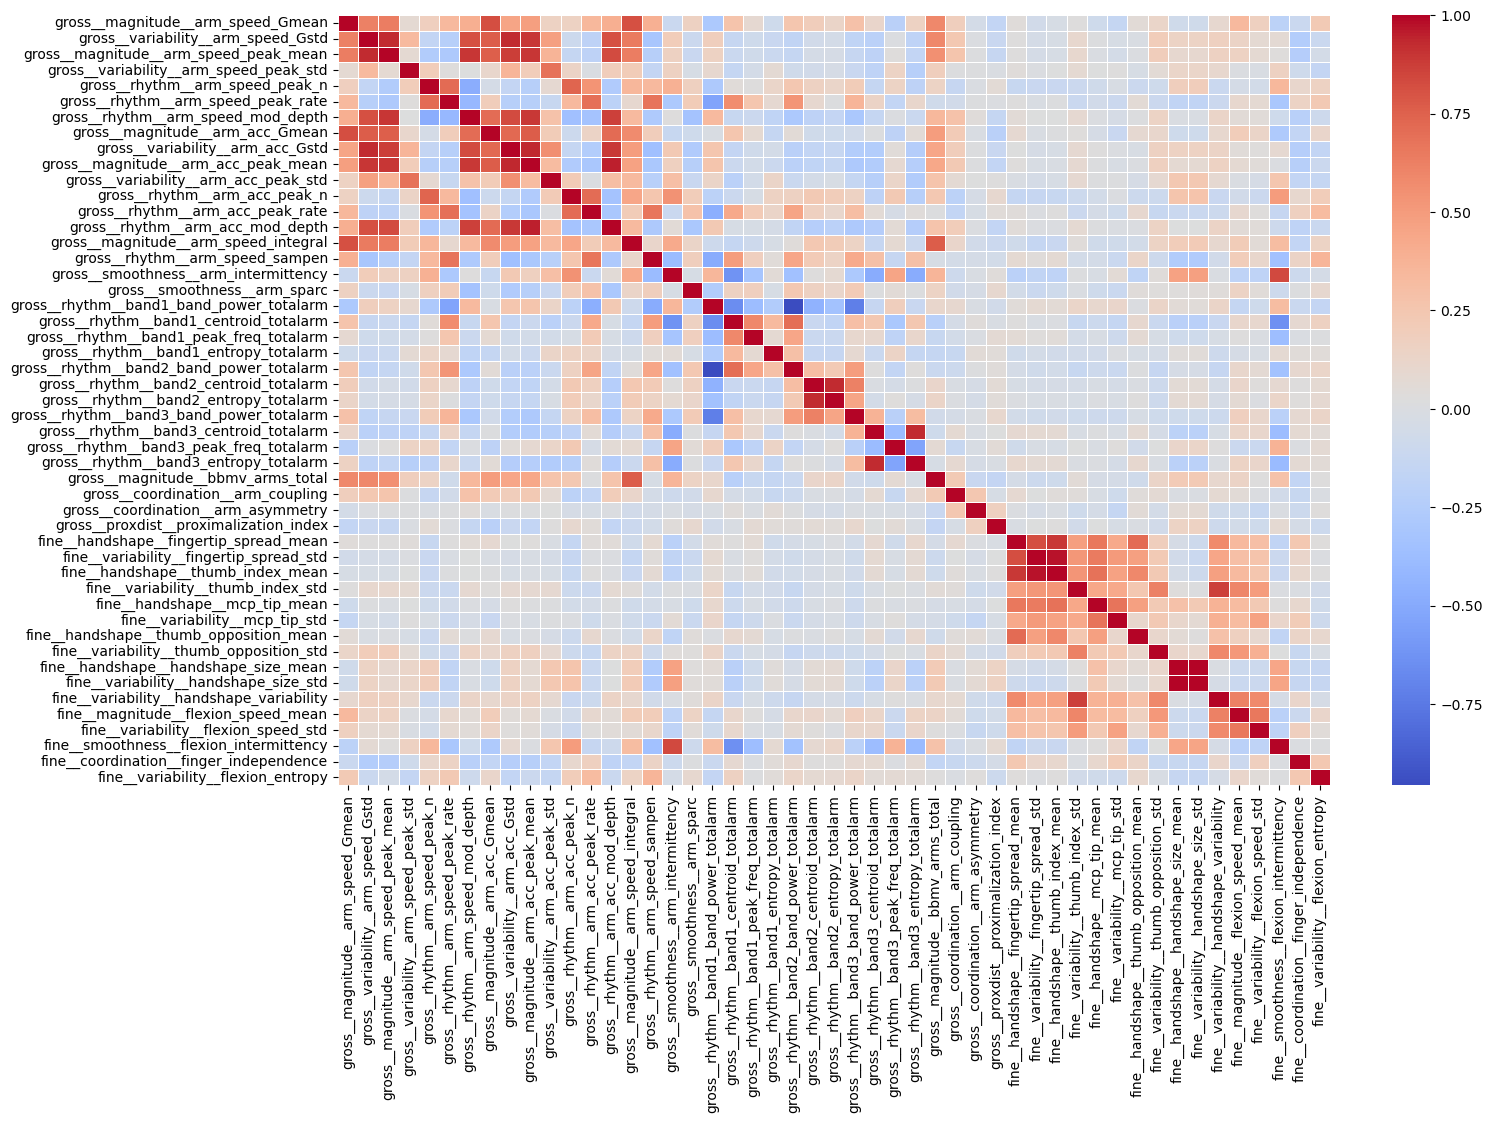

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

corr = features_df_clean.select_dtypes('number').corr()

plt.figure(figsize=(16, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', linewidths=0.5)


There are some strong correlations in the dataset, but because (i) we use Principal Component Analysis that re-organizes the features into orthogonal (uncorrelated) dimensions, and (ii) we are not primarily interested in detecting single best feature, we will keep all features in